# Cost / Rate Prediction

## Business objective

Predict `carrier_cost_usd` from information available when a shipment is quoted. The result supplies the estimated-cost component of the team's smart carrier recommendation system, where cost can be considered alongside transit time and late-delivery risk.

## Modeling plan

1. Validate the processed data and prevent target/future-outcome leakage.
2. Create reproducible 70% training, 15% validation, and 15% test splits.
3. Establish global-median, shipment-mode, and carrier/service median baselines.
4. Compare three CatBoost configurations and two LightGBM configurations on validation MAE.
5. Select the lowest-validation-MAE model without consulting the test set.
6. Evaluate the winner once on the held-out test set.
7. Analyze errors by carrier, shipment mode, service level, and cost band.

In [1]:
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

In [2]:
df = pd.read_csv("../notebooks/engineered_features.csv")

df.head()

,shipment_id,order_date,ship_date,ship_dow,ship_month,shipment_mode,carrier,service_level,origin_metro,dest_metro,origin_zip,dest_zip,origin_lat,origin_lon,dest_lat,dest_lon,distance_miles,zone,weight_lbs,length_in,width_in,height_in,pallet_count,residential_flag,signature_required,declared_value_usd,fuel_surcharge_pct,weather_severity,carrier_congestion_index,promised_days,carrier_cost_usd,transit_days,delivered_on_time,weight_lbs_na,length_in_na,width_in_na,height_in_na
0,SHP-42-0003885,2024-04-23,2024-04-23,1,4,parcel,Cobalt Regional,Overnight,Los Angeles CA,Salt Lake City UT,90041,84137,34.0500,-118.2400,40.7600,-111.8900,579.6000,4,2.4800,7.5000,4.3000,6.5000,0,1,0,0.0000,0.0954,0.1080,0.0000,2,29.5300,1,1,False,False,False,False
1,SHP-42-0010239,2025-01-07,2025-01-09,3,1,parcel,Northstar Parcel,Expedited,Seattle WA,New York NY,98167,10067,47.6100,-122.3300,40.7100,-74.0100,"2,401.7000",8,3.5700,10.9000,6.1000,4.2000,0,1,1,178.8700,0.1353,0.2730,0.2060,4,28.3000,3,1,False,False,False,False
2,SHP-42-0035486,2025-07-30,2025-07-30,2,7,ltl_freight,Vela Freight,LTL Standard,Atlanta GA,Miami FL,30358,33142,33.7500,-84.3900,25.7600,-80.1900,606.7000,5,202.7200,31.7000,33.0000,20.3000,1,0,0,0.0000,0.0727,0.2220,0.1190,9,205.0900,8,1,False,False,False,False
3,SHP-42-0008180,2025-03-24,2025-03-26,2,3,parcel,Northstar Parcel,Ground,New York NY,Salt Lake City UT,10043,84144,40.7100,-74.0100,40.7600,-111.8900,"1,967.5000",8,3.5300,9.8000,5.3000,4.7000,0,0,0,110.1200,0.0917,0.0460,0.2870,7,11.7900,6,1,False,False,False,False
4,SHP-42-0015190,2025-05-06,2025-05-08,3,5,parcel,Falcon Post,Expedited,Los Angeles CA,Columbus OH,90058,43209,34.0500,-118.2400,39.9600,-82.9900,"1,974.0000",8,6.3900,7.1000,6.2000,7.7000,0,0,0,14.8300,0.1213,0.2730,0.1200,4,13.1300,6,0,False,False,False,False


## 1. Data and target audit

The target is a continuous dollar amount, so this is a regression task. MAE is the primary business metric because it states the average absolute prediction error in dollars. RMSE is included to emphasize unusually large mistakes, and R² measures explained variance.

In [3]:
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Duplicate shipment IDs: {df['shipment_id'].duplicated().sum():,}")
print(f"Total missing values: {df.isna().sum().sum():,}")

df["carrier_cost_usd"].describe().to_frame(name="carrier_cost_usd")

Rows: 39,747
Columns: 37
Duplicate shipment IDs: 0
Total missing values: 0


,carrier_cost_usd
count,"39,747.0000"
mean,61.5311
std,105.9946
min,3.0000
25%,14.6300
50%,19.6500
75%,29.6100
max,695.0000


,count,mean,median,std,min,max
shipment_mode,,,,,,
ltl_freight,5886,301.7458,286.6100,88.0094,133.5300,695.0000
parcel,33861,19.7750,18.0400,8.2023,3.0000,94.9800


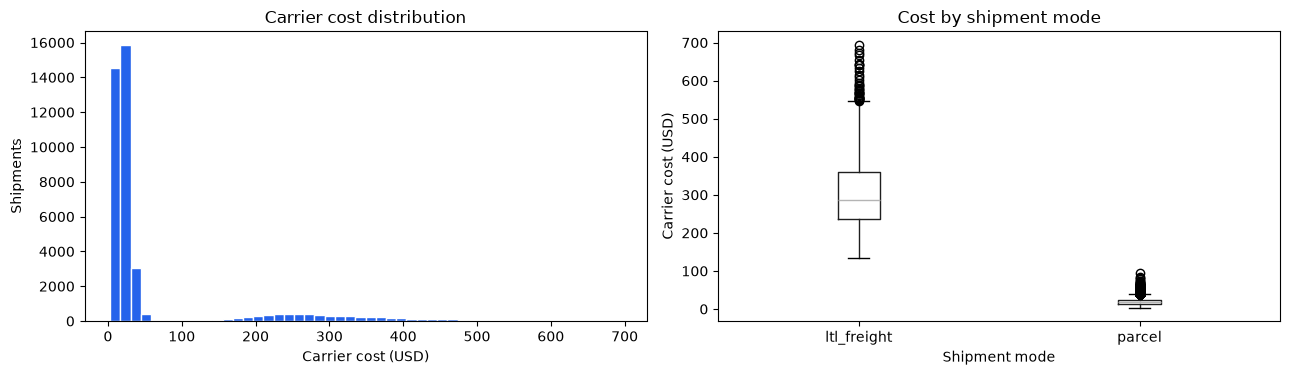

In [4]:
mode_cost_summary = (
    df.groupby("shipment_mode")["carrier_cost_usd"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)
display(mode_cost_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["carrier_cost_usd"], bins=50, color="#2563eb", edgecolor="white")
axes[0].set(title="Carrier cost distribution", xlabel="Carrier cost (USD)", ylabel="Shipments")

df.boxplot(column="carrier_cost_usd", by="shipment_mode", ax=axes[1], grid=False)
axes[1].set(title="Cost by shipment mode", xlabel="Shipment mode", ylabel="Carrier cost (USD)")
fig.suptitle("")
plt.tight_layout()
plt.show()

## 2. Leakage-safe feature set

Only information available at quote/selection time is used. The target and post-delivery outcomes (`transit_days` and `delivered_on_time`) are explicitly forbidden. Identifiers and raw dates are omitted; calendar effects are represented by `ship_dow` and `ship_month`.

In [5]:
TARGET = "carrier_cost_usd"

categorical_features = [
    "shipment_mode",
    "carrier",
    "service_level",
    "origin_metro",
    "dest_metro",
]

numeric_features = [
    "ship_dow",
    "ship_month",
    "distance_miles",
    "zone",
    "weight_lbs",
    "length_in",
    "width_in",
    "height_in",
    "pallet_count",
    "residential_flag",
    "signature_required",
    "declared_value_usd",
    "fuel_surcharge_pct",
    "weather_severity",
    "carrier_congestion_index",
    "promised_days",
]

features = categorical_features + numeric_features
forbidden_features = {
    TARGET,
    "transit_days",
    "delivered_on_time",
    "cost_per_mile",
    "cost_per_billable_lb",
}

assert forbidden_features.isdisjoint(features), "A leakage feature entered the model."
assert set(features).issubset(df.columns), "A selected feature is missing from the data."
assert df[features + [TARGET]].isna().sum().sum() == 0, "Modeling data contains missing values."
assert (df[TARGET] >= 0).all(), "Carrier cost must be nonnegative."

print(f"Selected {len(features)} features: {len(categorical_features)} categorical and {len(numeric_features)} numeric.")

Selected 21 features: 5 categorical and 16 numeric.


## 3. Reproducible train/validation/test split

Training data teaches each model. Validation data selects the model and configuration. The test set remains untouched until the winner has been selected.

In [6]:
SEED = 1234

train, holdout = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
)
val, test = train_test_split(
    holdout,
    test_size=0.50,
    random_state=SEED,
)

train_ids = set(train["shipment_id"])
val_ids = set(val["shipment_id"])
test_ids = set(test["shipment_id"])
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert len(train) + len(val) + len(test) == len(df)

split_summary = pd.DataFrame(
    {
        "Rows": [len(train), len(val), len(test)],
        "Percent": [len(train) / len(df), len(val) / len(df), len(test) / len(df)],
    },
    index=["Train", "Validation", "Test"],
)
split_summary

,Rows,Percent
Train,27822,0.7000
Validation,5962,0.1500
Test,5963,0.1500


## 4. Simple baselines

A useful model must beat more than one trivial strategy. The global median is the requested baseline, while shipment-mode and carrier/service medians are stronger operational benchmarks because parcel and LTL pricing are very different. All medians are learned from the training set only.

In [7]:
def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }


def nonnegative_predictions(model, model_input):
    return np.clip(model.predict(model_input), a_min=0, a_max=None)


def grouped_median_predictions(reference, scoring, group_columns):
    global_median = reference[TARGET].median()
    if not group_columns:
        return np.full(len(scoring), global_median)

    group_medians = reference.groupby(group_columns)[TARGET].median()
    if len(group_columns) == 1:
        predictions = scoring[group_columns[0]].map(group_medians)
    else:
        group_keys = pd.MultiIndex.from_frame(scoring[group_columns])
        predictions = pd.Series(group_keys.map(group_medians), index=scoring.index)
    return predictions.fillna(global_median).to_numpy()


baseline_groupings = {
    "Global median baseline": [],
    "Shipment-mode median baseline": ["shipment_mode"],
    "Carrier-service median baseline": ["carrier", "service_level"],
}
baseline_metrics_by_name = {}
baseline_rows = []

for name, grouping in baseline_groupings.items():
    predictions = grouped_median_predictions(train, val, grouping)
    metrics = regression_metrics(val[TARGET], predictions)
    baseline_metrics_by_name[name] = metrics
    baseline_rows.append(
        {
            "Model": name,
            "Validation MAE": metrics["MAE"],
            "Validation RMSE": metrics["RMSE"],
            "Validation R2": metrics["R2"],
            "Best iteration": np.nan,
            "Training seconds": 0.0,
        }
    )

baseline_comparison = pd.DataFrame(baseline_rows).sort_values("Validation MAE")
strongest_baseline_name = baseline_comparison.iloc[0]["Model"]
strongest_baseline_metrics = baseline_metrics_by_name[strongest_baseline_name]
global_baseline_metrics = baseline_metrics_by_name["Global median baseline"]
display(baseline_comparison[["Model", "Validation MAE", "Validation RMSE", "Validation R2"]])
print(f"Strongest simple baseline: {strongest_baseline_name}")

,Model,Validation MAE,Validation RMSE,Validation R2
2,Carrier-service median baseline,12.8151,32.7576,0.9017
1,Shipment-mode median baseline,15.4054,34.2454,0.8926
0,Global median baseline,46.5746,112.3385,-0.1559


Strongest simple baseline: Carrier-service median baseline


## 5. CatBoost experiments

CatBoost natively handles categorical values. Three controlled configurations test the effects of loss function and tree depth while keeping the feature set and data split fixed.

In [8]:
candidate_models = {}
candidate_rows = []

catboost_configs = {
    "CatBoost MAE (depth 6)": {"loss_function": "MAE", "depth": 6},
    "CatBoost RMSE (depth 6)": {"loss_function": "RMSE", "depth": 6},
    "CatBoost MAE (depth 8)": {"loss_function": "MAE", "depth": 8},
}

for name, config in catboost_configs.items():
    started = time.perf_counter()
    model = CatBoostRegressor(
        iterations=2_000,
        learning_rate=0.05,
        depth=config["depth"],
        loss_function=config["loss_function"],
        eval_metric="MAE",
        random_seed=SEED,
        early_stopping_rounds=100,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
    )
    model.fit(
        train[features],
        train[TARGET],
        cat_features=categorical_features,
        eval_set=(val[features], val[TARGET]),
    )
    predictions = nonnegative_predictions(model, val[features])
    metrics = regression_metrics(val[TARGET], predictions)
    elapsed = time.perf_counter() - started

    candidate_models[name] = model
    candidate_rows.append(
        {
            "Model": name,
            "Validation MAE": metrics["MAE"],
            "Validation RMSE": metrics["RMSE"],
            "Validation R2": metrics["R2"],
            "Best iteration": model.get_best_iteration(),
            "Training seconds": elapsed,
        }
    )
    print(f"{name}: MAE=${metrics['MAE']:,.2f}, RMSE=${metrics['RMSE']:,.2f}, R²={metrics['R2']:.4f}")

CatBoost MAE (depth 6): MAE=$1.61, RMSE=$2.94, R²=0.9992


CatBoost RMSE (depth 6): MAE=$1.32, RMSE=$2.14, R²=0.9996


CatBoost MAE (depth 8): MAE=$1.66, RMSE=$3.19, R²=0.9991


## 6. LightGBM experiments

LightGBM provides a second gradient-boosting implementation. L1 and L2 objectives are compared using the same features and split. Categorical levels are fixed across all splits so their integer codes remain consistent.

In [9]:
category_levels = {
    column: sorted(train[column].astype(str).unique())
    for column in categorical_features
}


def prepare_lightgbm_features(frame):
    prepared = frame[features].copy()
    for column in categorical_features:
        prepared[column] = pd.Categorical(
            prepared[column].astype(str),
            categories=category_levels[column],
        )
    return prepared


X_train_lgb = prepare_lightgbm_features(train)
X_val_lgb = prepare_lightgbm_features(val)
X_test_lgb = prepare_lightgbm_features(test)

In [10]:
lightgbm_configs = {
    "LightGBM L1": {"objective": "regression_l1", "num_leaves": 31},
    "LightGBM L2": {"objective": "regression", "num_leaves": 31},
}

for name, config in lightgbm_configs.items():
    started = time.perf_counter()
    model = lgb.LGBMRegressor(
        objective=config["objective"],
        n_estimators=3_000,
        learning_rate=0.03,
        num_leaves=config["num_leaves"],
        min_child_samples=20,
        colsample_bytree=0.90,
        reg_lambda=0.10,
        random_state=SEED,
        n_jobs=-1,
        verbosity=-1,
    )
    model.fit(
        X_train_lgb,
        train[TARGET],
        eval_X=X_val_lgb,
        eval_y=val[TARGET],
        eval_metric="mae",
        categorical_feature=categorical_features,
        callbacks=[
            lgb.early_stopping(100, verbose=False),
            lgb.log_evaluation(period=0),
        ],
    )
    predictions = nonnegative_predictions(model, X_val_lgb)
    metrics = regression_metrics(val[TARGET], predictions)
    elapsed = time.perf_counter() - started

    candidate_models[name] = model
    candidate_rows.append(
        {
            "Model": name,
            "Validation MAE": metrics["MAE"],
            "Validation RMSE": metrics["RMSE"],
            "Validation R2": metrics["R2"],
            "Best iteration": model.best_iteration_,
            "Training seconds": elapsed,
        }
    )
    print(f"{name}: MAE=${metrics['MAE']:,.2f}, RMSE=${metrics['RMSE']:,.2f}, R²={metrics['R2']:.4f}")

LightGBM L1: MAE=$1.65, RMSE=$3.13, R²=0.9991


LightGBM L2: MAE=$1.52, RMSE=$2.97, R²=0.9992


## 7. Validation comparison and model selection

The winner is selected strictly by lowest validation MAE. Three simple baselines are shown for context but are not trainable candidates.

,Model,Validation MAE,Validation RMSE,Validation R2,Best iteration,Training seconds
0,CatBoost RMSE (depth 6),1.3216,2.1367,0.9996,"1,987.0000",10.3624
1,LightGBM L2,1.5151,2.9667,0.9992,542.0000,2.2871
2,CatBoost MAE (depth 6),1.6099,2.9417,0.9992,"1,999.0000",11.9815
3,LightGBM L1,1.6533,3.1302,0.9991,"2,984.0000",10.6861
4,CatBoost MAE (depth 8),1.6575,3.1879,0.9991,"1,998.0000",17.8152
5,Carrier-service median baseline,12.8151,32.7576,0.9017,NaN,0.0000
6,Shipment-mode median baseline,15.4054,34.2454,0.8926,NaN,0.0000
7,Global median baseline,46.5746,112.3385,-0.1559,NaN,0.0000


Selected model: CatBoost RMSE (depth 6)
Validation MAE: $1.32
Improvement over strongest simple baseline: 89.7%
Improvement over global median baseline: 97.2%


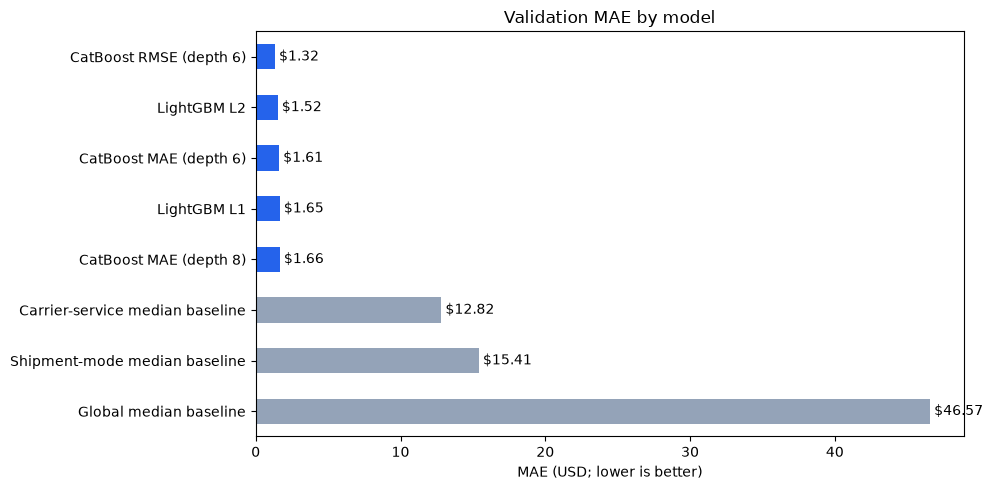

In [11]:
comparison = (
    pd.DataFrame(baseline_rows + candidate_rows)
    .sort_values("Validation MAE")
    .reset_index(drop=True)
)
display(comparison)

best_row = pd.DataFrame(candidate_rows).sort_values("Validation MAE").iloc[0]
best_model_name = best_row["Model"]
best_model = candidate_models[best_model_name]
validation_improvement_pct = (
    (strongest_baseline_metrics["MAE"] - best_row["Validation MAE"])
    / strongest_baseline_metrics["MAE"]
    * 100
)
global_validation_improvement_pct = (
    (global_baseline_metrics["MAE"] - best_row["Validation MAE"])
    / global_baseline_metrics["MAE"]
    * 100
)

print(f"Selected model: {best_model_name}")
print(f"Validation MAE: ${best_row['Validation MAE']:,.2f}")
print(f"Improvement over strongest simple baseline: {validation_improvement_pct:.1f}%")
print(f"Improvement over global median baseline: {global_validation_improvement_pct:.1f}%")

plot_data = comparison.sort_values("Validation MAE", ascending=False)
colors = ["#94a3b8" if "baseline" in name.lower() else "#2563eb" for name in plot_data["Model"]]
ax = plot_data.plot.barh(
    x="Model",
    y="Validation MAE",
    figsize=(10, 5),
    color=colors,
    legend=False,
)
ax.set(title="Validation MAE by model", xlabel="MAE (USD; lower is better)", ylabel="")
for container in ax.containers:
    ax.bar_label(container, fmt="$%.2f", padding=3)
plt.tight_layout()
plt.show()

## 8. Final held-out test evaluation

Only the selected validation winner is now evaluated on the test set. Predictions are clipped at zero to enforce the nonnegative-cost business constraint.

In [12]:
if best_model_name.startswith("LightGBM"):
    test_model_input = X_test_lgb
else:
    test_model_input = test[features]

test_predictions = nonnegative_predictions(best_model, test_model_input)
test_metrics = regression_metrics(test[TARGET], test_predictions)
global_test_predictions = grouped_median_predictions(train, test, [])
strongest_baseline_test_predictions = grouped_median_predictions(
    train, test, baseline_groupings[strongest_baseline_name]
)
global_test_metrics = regression_metrics(test[TARGET], global_test_predictions)
strongest_baseline_test_metrics = regression_metrics(
    test[TARGET], strongest_baseline_test_predictions
)
test_improvement_pct = (
    (strongest_baseline_test_metrics["MAE"] - test_metrics["MAE"])
    / strongest_baseline_test_metrics["MAE"]
    * 100
)
global_test_improvement_pct = (
    (global_test_metrics["MAE"] - test_metrics["MAE"])
    / global_test_metrics["MAE"]
    * 100
)

test_scorecard = pd.DataFrame(
    {
        "Metric": ["MAE (USD)", "RMSE (USD)", "R²"],
        "Global median baseline": [
            global_test_metrics["MAE"],
            global_test_metrics["RMSE"],
            global_test_metrics["R2"],
        ],
        strongest_baseline_name: [
            strongest_baseline_test_metrics["MAE"],
            strongest_baseline_test_metrics["RMSE"],
            strongest_baseline_test_metrics["R2"],
        ],
        best_model_name: [test_metrics["MAE"], test_metrics["RMSE"], test_metrics["R2"]],
    }
)
display(test_scorecard)
print(f"Test improvement over strongest simple baseline: {test_improvement_pct:.1f}%")
print(f"Test improvement over global median baseline: {global_test_improvement_pct:.1f}%")

,Metric,Global median baseline,Carrier-service median baseline,CatBoost RMSE (depth 6)
0,MAE (USD),46.4986,12.8980,1.3339
1,RMSE (USD),113.4226,33.4945,2.3015
2,R²,-0.1526,0.8995,0.9995


Test improvement over strongest simple baseline: 89.7%
Test improvement over global median baseline: 97.1%


## 9. Error analysis

MAE is broken down by operational segment to identify where the model is least reliable. Bias is `predicted - actual`: positive values indicate overprediction and negative values indicate underprediction.

In [13]:
results = test[
    [
        "shipment_id",
        "shipment_mode",
        "carrier",
        "service_level",
        "distance_miles",
        "weight_lbs",
        TARGET,
    ]
].copy()
results["predicted_cost"] = test_predictions
results["signed_error"] = results["predicted_cost"] - results[TARGET]
results["absolute_error"] = results["signed_error"].abs()
results["cost_band"] = pd.cut(
    results[TARGET],
    bins=[0, 25, 75, np.inf],
    labels=["Up to $25", "$25 to $75", "Over $75"],
    include_lowest=True,
)

results.head()

,shipment_id,shipment_mode,carrier,service_level,distance_miles,weight_lbs,carrier_cost_usd,predicted_cost,signed_error,absolute_error,cost_band
11427,SHP-42-0012354,parcel,Summit Express,Ground,"1,742.2000",3.2200,26.8500,25.4434,-1.4066,1.4066,$25 to $75
21348,SHP-42-0023753,parcel,Cobalt Regional,Expedited,585.4000,2.9300,15.1500,16.5741,1.4241,1.4241,Up to $25
21332,SHP-42-0000988,parcel,Falcon Post,Ground,436.0000,2.6000,13.4800,12.0519,-1.4281,1.4281,Up to $25
2292,SHP-42-0008409,parcel,Falcon Post,TwoDay,908.1000,3.5100,20.5200,19.3932,-1.1268,1.1268,Up to $25
6073,SHP-42-0043198,parcel,Falcon Post,Expedited,"2,139.4000",3.1500,17.7000,16.4939,-1.2061,1.2061,Up to $25


In [14]:
def segment_error_table(column):
    return (
        results.groupby(column, observed=False)
        .agg(
            Shipments=("absolute_error", "size"),
            Actual_mean=(TARGET, "mean"),
            Predicted_mean=("predicted_cost", "mean"),
            MAE=("absolute_error", "mean"),
            Median_AE=("absolute_error", "median"),
            Bias=("signed_error", "mean"),
        )
        .sort_values("MAE", ascending=False)
    )


print("Error by carrier")
display(segment_error_table("carrier"))
print("Error by shipment mode")
display(segment_error_table("shipment_mode"))
print("Error by service level")
display(segment_error_table("service_level"))
print("Error by actual-cost band")
display(segment_error_table("cost_band"))

Error by carrier


,Shipments,Actual_mean,Predicted_mean,MAE,Median_AE,Bias
carrier,,,,,,
Vela Freight,359,332.0841,331.4555,2.9487,2.0003,-0.6286
Ironclad Freight,505,283.0351,283.1220,2.4595,1.5993,0.0869
Cobalt Regional,177,17.7222,18.2162,1.1955,0.9771,0.4940
Summit Express,1189,26.2585,26.2816,1.1709,0.9404,0.0231
Northstar Parcel,1672,19.8574,19.8296,1.1047,0.9165,-0.0278
Falcon Post,2061,16.4151,16.4069,1.0686,0.8789,-0.0082


Error by shipment mode


,Shipments,Actual_mean,Predicted_mean,MAE,Median_AE,Bias
shipment_mode,,,,,,
ltl_freight,864,303.4154,303.2050,2.6628,1.7709,-0.2104
parcel,5099,19.8845,19.8946,1.1087,0.9063,0.0101


Error by service level


,Shipments,Actual_mean,Predicted_mean,MAE,Median_AE,Bias
service_level,,,,,,
LTL Guaranteed,217,292.3577,292.4832,2.9402,2.2562,0.1255
LTL Standard,647,307.1241,306.8011,2.5697,1.5901,-0.3230
Expedited,973,20.0562,19.9790,1.1364,0.9279,-0.0772
TwoDay,770,24.6107,24.6872,1.1250,0.8993,0.0765
Overnight,526,34.0337,34.0857,1.1171,0.8920,0.0520
Ground,2830,15.9097,15.9240,1.0932,0.9113,0.0143


Error by actual-cost band


,Shipments,Actual_mean,Predicted_mean,MAE,Median_AE,Bias
cost_band,,,,,,
Over $75,864,303.4154,303.2050,2.6628,1.7709,-0.2104
$25 to $75,1135,32.2773,32.0076,1.2573,0.9743,-0.2697
Up to $25,3964,16.3361,16.4263,1.0661,0.8883,0.0902


In [15]:
worst_errors = results.nlargest(10, "absolute_error")[
    [
        "shipment_id",
        "shipment_mode",
        "carrier",
        "service_level",
        "distance_miles",
        "weight_lbs",
        TARGET,
        "predicted_cost",
        "absolute_error",
    ]
]
worst_errors

,shipment_id,shipment_mode,carrier,service_level,distance_miles,weight_lbs,carrier_cost_usd,predicted_cost,absolute_error
25516,SHP-42-0010826,ltl_freight,Ironclad Freight,LTL Guaranteed,"1,521.2000","553,637.0000",378.3000,428.9063,50.6063
39455,SHP-42-0032745,ltl_freight,Vela Freight,LTL Standard,"2,401.7000","2,378.1700",643.1400,601.5964,41.5436
19740,SHP-42-0019525,ltl_freight,Vela Freight,LTL Standard,"1,093.4000",471.2285,394.9400,353.7530,41.1870
4998,SHP-42-0026904,ltl_freight,Vela Freight,LTL Standard,"2,445.3000","2,244.3700",642.0100,603.0110,38.9990
2965,SHP-42-0020933,ltl_freight,Vela Freight,LTL Standard,"1,723.7000","2,322.8000",536.4200,502.0106,34.4094
249,SHP-42-0011208,ltl_freight,Ironclad Freight,LTL Standard,665.4000,471.2285,255.3900,224.2983,31.0917
1642,SHP-42-0017652,ltl_freight,Vela Freight,LTL Standard,719.6000,"3,008.5800",484.2700,457.1844,27.0856
29235,SHP-42-0005767,ltl_freight,Ironclad Freight,LTL Guaranteed,"1,978.8000",471.2285,409.7900,387.1887,22.6013
17598,SHP-42-0042362,ltl_freight,Vela Freight,LTL Standard,"2,401.7000","1,422.0700",555.3300,533.5763,21.7537
26958,SHP-42-0035786,ltl_freight,Vela Freight,LTL Standard,"2,590.7000","1,376.8300",587.5600,567.4581,20.1019


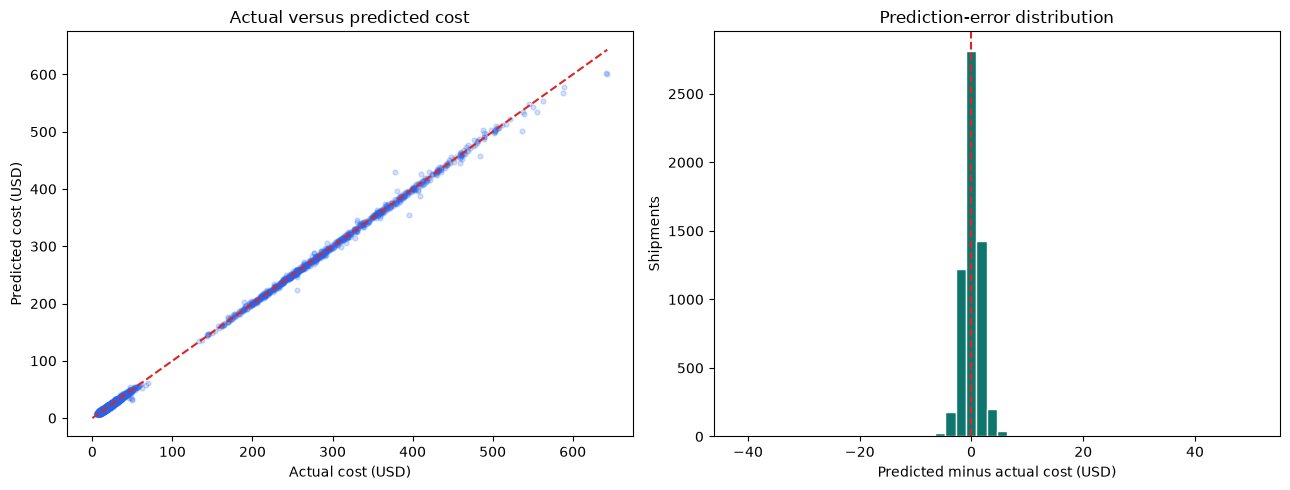

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    results[TARGET],
    results["predicted_cost"],
    alpha=0.20,
    s=12,
    color="#2563eb",
)
axis_limit = max(results[TARGET].max(), results["predicted_cost"].max())
axes[0].plot([0, axis_limit], [0, axis_limit], linestyle="--", color="#dc2626")
axes[0].set(
    title="Actual versus predicted cost",
    xlabel="Actual cost (USD)",
    ylabel="Predicted cost (USD)",
)

axes[1].hist(results["signed_error"], bins=50, color="#0f766e", edgecolor="white")
axes[1].axvline(0, linestyle="--", color="#dc2626")
axes[1].set(
    title="Prediction-error distribution",
    xlabel="Predicted minus actual cost (USD)",
    ylabel="Shipments",
)

plt.tight_layout()
plt.show()

## 10. Feature importance

Importance values describe how much the selected model used each input. They are useful for model interpretation but do not, by themselves, establish causality.

,Importance
shipment_mode,46.4678
pallet_count,43.1563
distance_miles,5.2361
zone,1.8537
carrier,0.9414
weight_lbs,0.7200
promised_days,0.5391
length_in,0.3405
width_in,0.2172
fuel_surcharge_pct,0.1469


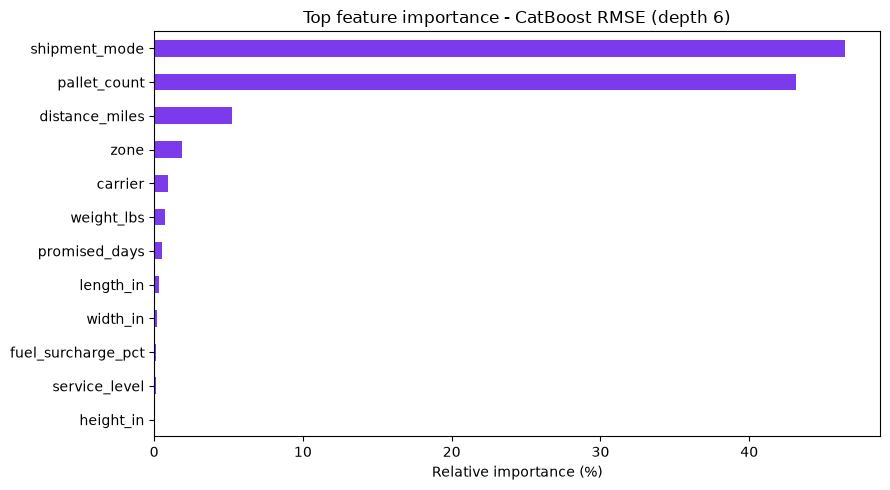

In [17]:
if best_model_name.startswith("CatBoost"):
    raw_importance = best_model.get_feature_importance()
else:
    raw_importance = best_model.feature_importances_

feature_importance = (
    pd.Series(raw_importance, index=features, name="Importance")
    .sort_values(ascending=False)
)
feature_importance = feature_importance / feature_importance.sum() * 100
display(feature_importance.to_frame())

top_importance = feature_importance.head(12).sort_values()
ax = top_importance.plot.barh(figsize=(9, 5), color="#7c3aed")
ax.set(title=f"Top feature importance - {best_model_name}", xlabel="Relative importance (%)", ylabel="")
plt.tight_layout()
plt.show()

## 11. Example prediction

One held-out shipment demonstrates how the output would appear inside a future carrier-comparison workflow.

In [18]:
median_absolute_error = results["absolute_error"].median()
example_position = int(
    np.argmin(np.abs(results["absolute_error"].to_numpy() - median_absolute_error))
)
example = results.iloc[example_position]

display(
    pd.DataFrame(
        {
            "Field": [
                "Shipment ID",
                "Carrier",
                "Service level",
                "Shipment mode",
                "Distance (miles)",
                "Weight (lbs)",
                "Predicted cost",
                "Actual cost",
            ],
            "Value": [
                example["shipment_id"],
                example["carrier"],
                example["service_level"],
                example["shipment_mode"],
                f"{example['distance_miles']:,.0f}",
                f"{example['weight_lbs']:,.1f}",
                f"${example['predicted_cost']:,.2f}",
                f"${example[TARGET]:,.2f}",
            ],
        }
    )
)

,Field,Value
0,Shipment ID,SHP-42-0049745
1,Carrier,Vela Freight
2,Service level,LTL Standard
3,Shipment mode,ltl_freight
4,Distance (miles),647
5,Weight (lbs),908.2
6,Predicted cost,$263.62
7,Actual cost,$264.61


## 12. Final summary

Three CatBoost configurations and two LightGBM configurations were compared with three simple baselines. CatBoost RMSE with depth 6 produced the lowest validation MAE.

- Validation MAE: $1.32
- Validation improvement over the carrier-service median baseline: 89.7%
- Test MAE: $1.33
- Test RMSE: $2.30
- Test R²: 0.9995
- Test improvement over the strongest simple baseline: 89.7%

The three most influential features were shipment_mode, pallet_count, and distance_miles. Vela Freight had the highest carrier-level MAE, and ltl_freight had the highest shipment-mode MAE.

The model supplies the estimated-cost component of the carrier recommendation system. Cost should be considered with predicted transit time and late-delivery risk.

### Limitations and next steps

- The near-perfect R² reflects the strong structure of this synthetic dataset and should not be assumed to transfer directly to real invoices.
- Performance was measured on a random held-out sample from the same dataset. Future work should validate on later shipments and newly collected invoices.
- Weather severity and carrier congestion are valid inputs only if they are available when a quote is created.
- High-cost shipments are less common and may have larger dollar errors.
- A production workflow should retrain the selected configuration on approved historical data, version the model artifact, and monitor cost drift.